# Lecture 7. Accelerated first-order methods

**Convex optimization, Fall 2026**

- Lecture 6 proved what a gradient step gets on an $L$-smooth function, on an $L$-smooth convex function, and on an $L$-smooth strongly convex function.
- Those proofs are upper bounds. Each one says that a particular iteration drives a particular residual down at a particular rate, on every function in the class.
- A lower bound says the opposite: some function in the class forces every first-order method to leave at least this much residual after $k$ gradients.
- Today the lower bound is a concrete quadratic, and the methods are the ones that meet it: conjugate gradients, Polyak's heavy ball, and Nesterov's acceleration.
- Notation is unchanged. $\|\cdot\|$ is the Euclidean norm, $f'$ is the gradient, $f^\star$ is the optimal value, $\kappa=L/\mu$.


## Plan

1. Lower bounds, and the worst function in the $L$-smooth convex class
2. Conjugate gradients on a quadratic, then the nonlinear method and its line search
3. The heavy-ball method: the quadratic rate, the transient, and a smooth strongly convex cycle
4. Nesterov's acceleration: the $1/k^2$ potential, the strongly convex rate, and the ripple a restart removes
5. Which method to run

- The notebook uses NumPy and Matplotlib only.
- Every method below forms the next point from the start and the gradients it has already seen. That restriction is the hypothesis of the lower bound, and all four methods satisfy it.


In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "figure.figsize": (7.2, 4.0),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 12,
        "axes.titlesize": 13,
        "legend.fontsize": 10,
    }
)


# 1. A lower bound is a function

- An **upper bound** is a theorem about an iteration: for every $f$ in the class, the residual after $k$ steps is at most something.
- A **lower bound** is a theorem about the class: for every iteration of a certain kind, there exists an $f$ in the class on which the residual after $k$ steps is still at least something.
- The iteration kind in this lecture is a **span-restricted** first-order method. It may call the oracle $\mathbf{x}\mapsto\bigl(f(\mathbf{x}), f'(\mathbf{x})\bigr)$ at any point it builds, and the point it builds for the next call has to lie in

$$
\mathbf{x}^{0}+\mathrm{span}\bigl\{f'(\mathbf{y}^{0}),\ldots,f'(\mathbf{y}^{k-1})\bigr\},
$$

where $\mathbf{y}^{0},\ldots,\mathbf{y}^{k-1}$ are the points already queried.

- Gradient descent, conjugate gradients, the heavy ball, and Nesterov's method all have this form. A method that is handed $\mathbf{x}^\star$, or the Hessian, or a random direction with a component outside that span, is a **different** kind of method, and this lower bound does not speak about it.
- Matching means the power of $k$, or of $\kappa$, agrees. The constant in front of that power is a separate question, and on the function below it can be read off exactly.


## The resisting function

- Fix a horizon $t$ and a smoothness constant $L>0$. On $\mathbb{R}^{t}$,

$$
f_t(\mathbf{x})
=\frac{L}{8}\,\mathbf{x}^{\!\top}\mathbf{B}\,\mathbf{x}-\frac{L}{4}\,x_1,
\qquad
\mathbf{B}
=\mathrm{tridiag}(-1,2,-1).
$$

- $\mathbf{B}$ is the second-difference matrix: $2$ on the diagonal, $-1$ on the two off-diagonals. Its eigenvalues lie in $(0,4)$, so the eigenvalues of $f_t''=(L/4)\mathbf{B}$ lie in $(0,L)$.
- $f_t$ is convex and $L$-smooth. It is the standard worst function for this class (Nesterov, *Lectures on Convex Optimization*, §2.1).
- The minimizer solves $\mathbf{B}\,\mathbf{x}^\star=\mathbf{e}_1$, and it is the straight line

$$
x^\star_i=\frac{t+1-i}{t+1},
\qquad
f_t^\star=-\frac{L}{8}\,\frac{t}{t+1}.
$$

- $\|\mathbf{x}^\star\|^2=t(2t+1)/\bigl(6(t+1)\bigr)$. The minimizer has mass on every coordinate. A method that has only seen the first few coordinates has not reached it.


## One new coordinate per gradient

- Start at $\mathbf{x}^{0}=\mathbf{0}$. Then $f_t'(\mathbf{0})=-(L/4)\,\mathbf{e}_1$.
- The first gradient has a single nonzero coordinate. A span-restricted method's first query, and its first iterate, lie on that coordinate axis.
- If a point has zeros past coordinate $k$, then $\mathbf{B}$ times that point has zeros past coordinate $k+1$, because $\mathbf{B}$ only couples neighbours. So $f_t'$ at that point has zeros past coordinate $k+1$.
- Each gradient reveals one new coordinate, and no method of this kind can skip ahead.
- After $k$ gradients, every query point and every iterate has zeros past coordinate $k$.
- On that subspace the best value is the optimum of the same problem in dimension $k$,

$$
f_t(\mathbf{x}^{k})-f_t^\star
\;\ge\;
\frac{L}{8}\left(\frac{t}{t+1}-\frac{k}{k+1}\right).
$$

- The right-hand side is zero when $k=t$: once every coordinate has been seen, the obstruction is gone.
- Conjugate gradients, defined in the next section, minimises $f_t$ over exactly this subspace. On $f_t$ the inequality is an equality for CG, and a strict inequality for gradient descent.


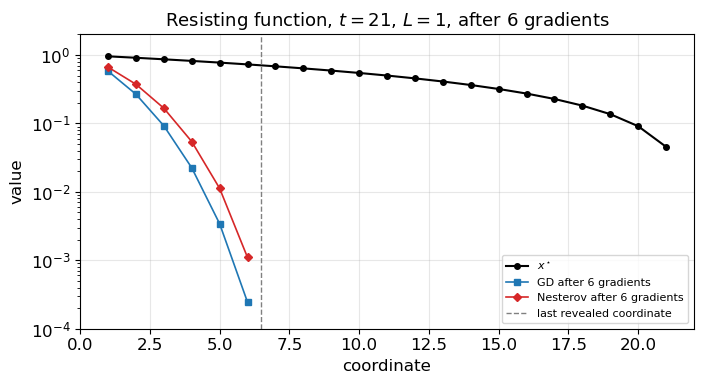

eigenvalues of f'' in (0.0051, 0.9949), condition number 195.5
f* = -0.119318, formula -0.119318
last nonzero coordinate: GD 6, CG 6, Nesterov 6
coordinate lower bound 1.217532e-02
gap GD       3.306344e-02   ratio to bound 2.716
gap CG       1.217532e-02   ratio to bound 1.000
gap Nesterov 2.616437e-02   ratio to bound 2.149


In [5]:
def resisting(t, L=1.0):
    # f = (L/8) x^T B x - (L/4) x_1, with B = tridiag(-1, 2, -1).
    B = np.zeros((t, t))
    idx = np.arange(t)
    B[idx, idx] = 2.0
    B[idx[:-1], idx[1:]] = -1.0
    B[idx[1:], idx[:-1]] = -1.0
    e0 = np.zeros(t)
    e0[0] = 1.0

    def f(x):
        return (L / 8.0) * np.dot(x, B @ x) - (L / 4.0) * x[0]

    def grad(x):
        return (L / 4.0) * (B @ x - e0)

    x_star = np.linalg.solve(B, e0)
    return f, grad, x_star, B


def run_resisting(t, n_steps, method, L=1.0):
    f, grad, x_star, B = resisting(t, L)
    f_star = f(x_star)
    x = np.zeros(t)
    if method == "gd":
        for _ in range(n_steps):
            x = x - grad(x) / L
        return x, f(x) - f_star, x_star, f_star
    if method == "cg":
        H = (L / 4.0) * B
        b = (L / 4.0) * np.eye(t)[0]
        g = H @ x - b
        d = -g.copy()
        for _ in range(n_steps):
            Hd = H @ d
            alpha = np.dot(g, g) / np.dot(d, Hd)
            x = x + alpha * d
            g_new = g + alpha * Hd
            beta = np.dot(g_new, g_new) / np.dot(g, g)
            d = -g_new + beta * d
            g = g_new
        return x, f(x) - f_star, x_star, f_star
    if method == "nesterov":
        y = x.copy()
        t_rec = 1.0
        for _ in range(n_steps):
            x_new = y - grad(y) / L
            t_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_rec * t_rec))
            beta = (t_rec - 1.0) / t_new
            y = x_new + beta * (x_new - x)
            x = x_new
            t_rec = t_new
        return x, f(x) - f_star, x_star, f_star
    raise ValueError(method)


def last_nonzero(x, tol=1e-10):
    nz = np.where(np.abs(x) > tol)[0]
    return int(nz[-1]) + 1 if len(nz) else 0


t_show, k_show, L_show = 21, 6, 1.0
x_gd, gap_gd, x_star, f_star = run_resisting(t_show, k_show, "gd", L_show)
x_cg, gap_cg, _, _ = run_resisting(t_show, k_show, "cg", L_show)
x_ne, gap_ne, _, _ = run_resisting(t_show, k_show, "nesterov", L_show)
coord_lb = (L_show / 8.0) * (t_show / (t_show + 1.0) - k_show / (k_show + 1.0))
eigs = np.linalg.eigvalsh((L_show / 4.0) * resisting(t_show, L_show)[3])

coord = np.arange(1, t_show + 1)
shown = lambda v: np.where(np.abs(v) > 1e-14, v, np.nan)
fig, ax = plt.subplots()
ax.semilogy(coord, shown(x_star), "o-", color="k", ms=4, lw=1.5, label=r"$x^\star$")
ax.semilogy(coord, shown(x_gd), "s-", color="C0", ms=4, lw=1.2, label=rf"GD after {k_show} gradients")
ax.semilogy(coord, shown(x_ne), "D-", color="C3", ms=4, lw=1.2, label=rf"Nesterov after {k_show} gradients")
ax.axvline(k_show + 0.5, color="0.5", ls="--", lw=1, label="last revealed coordinate")
ax.set_xlabel("coordinate")
ax.set_ylabel("value")
ax.set_ylim(1e-4, 2)
ax.set_title(rf"Resisting function, $t={t_show}$, $L={L_show:.0f}$, after {k_show} gradients")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"eigenvalues of f'' in ({eigs.min():.4f}, {eigs.max():.4f}), condition number {eigs.max()/eigs.min():.1f}")
print(f"f* = {f_star:.6f}, formula {-L_show/8 * t_show/(t_show+1):.6f}")
print(f"last nonzero coordinate: GD {last_nonzero(x_gd)}, CG {last_nonzero(x_cg)}, Nesterov {last_nonzero(x_ne)}")
print(f"coordinate lower bound {coord_lb:.6e}")
print(f"gap GD       {gap_gd:.6e}   ratio to bound {gap_gd/coord_lb:.3f}")
print(f"gap CG       {gap_cg:.6e}   ratio to bound {gap_cg/coord_lb:.3f}")
print(f"gap Nesterov {gap_ne:.6e}   ratio to bound {gap_ne/coord_lb:.3f}")


## Reading the coordinates

- The vertical axis is logarithmic. Gradient descent and Nesterov stop at the dashed line, after coordinate $6$: every later coordinate is still the initial value $0$, which a log axis does not draw. The print gives the same cutoff for conjugate gradients.
- $x^\star_i=(t+1-i)/(t+1)$ keeps decreasing through the unseen tail. Most of its mass sits to the right of the dashed line.
- The eigenvalues of $f''$ sit in $(0.005, 0.995)$, so this $f_{21}$ is in the class. Its condition number is $196$, of order $t^2$. A single fixed $f_t$ is strongly convex, and a long enough run does converge linearly. The lower bound stays informative only while $k$ is smaller than $t$.
- The coordinate lower bound equals $1.22\times 10^{-2}$. Conjugate gradients meets it with ratio $1.000$: on this quadratic the Krylov subspace after $k$ steps is the span of the first $k$ coordinates, and CG returns the minimiser of $f_t$ on that subspace.
- Gradient descent's gap is $2.72$ times the bound. Nesterov's is $2.15$ times the bound. Both live in the same subspace and use it less completely than CG. The Nesterov iteration is the convex scheme of section 4.


## From one function to a budget

- The coordinate bound, divided by $L\|\mathbf{x}^\star\|^2$, becomes a multiple of $1/k^2$ when the dimension grows with $k$.
- Take $t=2k+1$, so that $k=(t-1)/2$ is the largest horizon at which half the coordinates are still hidden. Then

$$
f_t(\mathbf{x}^{k})-f_t^\star
\;\ge\;
\frac{3L\,\|\mathbf{x}^{0}-\mathbf{x}^\star\|^2}{32\,(k+1)^2}.
$$

- The factor $3/32$ is this substitution, slightly weakened so that it holds for every such pair $(k,t)$. The plot compares it with the coordinate bound, which is the sharp one.
- Inverting it, a gap below $\varepsilon$ is not guaranteed before

$$
k\;\ge\;c\sqrt{\frac{L R^2}{\varepsilon}},
\qquad R=\|\mathbf{x}^{0}-\mathbf{x}^\star\|.
$$

- Lecture 6's gradient descent proves $f(\mathbf{x}^{k})-f^\star\le LR^2/(2k)$, which inverts to $k\ge LR^2/(2\varepsilon)$. The powers of $\varepsilon$ differ: one extra digit multiplies the gradient-descent budget by $10$, and the lower bound's budget by $\sqrt{10}$.
- Each point of the next figure is a **different** function. Dimension $t=2k+1$, one run of $k$ gradients, gap divided by that function's own $LR^2$. A single run on a single $f_t$ is the stem plot above, and it is a different object.


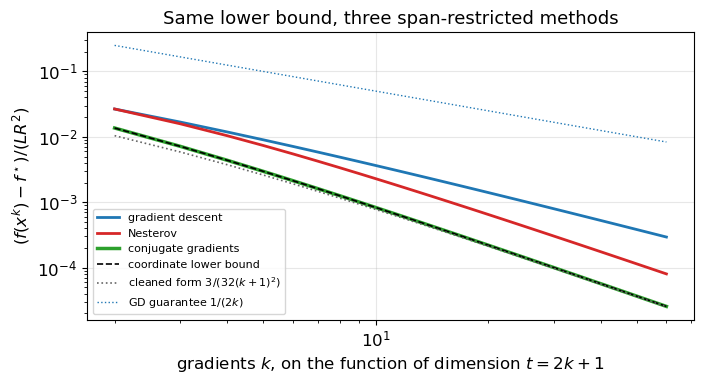

k=  5  GD 9.002e-03  Nesterov 7.368e-03  CG 2.964e-03  coordinate 2.964e-03  3/32 2.604e-03  GD guarantee 1.000e-01
k= 10  GD 3.642e-03  Nesterov 2.290e-03  CG 8.306e-04  coordinate 8.306e-04  3/32 7.748e-04  GD guarantee 5.000e-02
k= 20  GD 1.406e-03  Nesterov 6.495e-04  CG 2.204e-04  coordinate 2.204e-04  3/32 2.126e-04  GD guarantee 2.500e-02
k= 40  GD 5.263e-04  Nesterov 1.751e-04  CG 5.681e-05  coordinate 5.681e-05  3/32 5.577e-05  GD guarantee 1.250e-02
k= 60  GD 2.934e-04  Nesterov 8.009e-05  CG 2.551e-05  coordinate 2.551e-05  3/32 2.519e-05  GD guarantee 8.333e-03
max |CG / coordinate bound - 1| = 2.66e-14
at k=40, Nesterov / bound = 3.08
at k=40, GD / Nesterov = 3.01


In [6]:
ks = np.arange(2, 61)
rows = []
for k in ks:
    t = 2 * k + 1
    _, gap_gd_k, x_star_k, _ = run_resisting(t, k, "gd")
    _, gap_cg_k, _, _ = run_resisting(t, k, "cg")
    _, gap_ne_k, _, _ = run_resisting(t, k, "nesterov")
    R2 = np.dot(x_star_k, x_star_k)
    coord = (1.0 / 8.0) * (t / (t + 1.0) - k / (k + 1.0))
    rows.append((gap_gd_k / R2, gap_cg_k / R2, gap_ne_k / R2, coord / R2))
rows = np.array(rows)
gd_n, cg_n, ne_n, lb_n = rows.T
clean = 3.0 / (32.0 * (ks + 1.0) ** 2)
gd_guarantee = 1.0 / (2.0 * ks)

fig, ax = plt.subplots()
ax.loglog(ks, gd_n, color="C0", lw=2, label="gradient descent")
ax.loglog(ks, ne_n, color="C3", lw=2, label="Nesterov")
ax.loglog(ks, cg_n, color="C2", lw=2.5, label="conjugate gradients")
ax.loglog(ks, lb_n, color="k", ls="--", lw=1.2, label="coordinate lower bound")
ax.loglog(ks, clean, color="0.4", ls=":", lw=1.2, label=r"cleaned form $3/(32(k+1)^2)$")
ax.loglog(ks, gd_guarantee, color="C0", ls=":", lw=1, label=r"GD guarantee $1/(2k)$")
ax.set_xlabel(r"gradients $k$, on the function of dimension $t=2k+1$")
ax.set_ylabel(r"$(f(x^k)-f^\star)/(L R^2)$")
ax.set_title("Same lower bound, three span-restricted methods")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for k in (5, 10, 20, 40, 60):
    i = int(k - ks[0])
    print(
        f"k={k:3d}  GD {gd_n[i]:.3e}  Nesterov {ne_n[i]:.3e}  "
        f"CG {cg_n[i]:.3e}  coordinate {lb_n[i]:.3e}  "
        f"3/32 {(clean[i]):.3e}  GD guarantee {gd_guarantee[i]:.3e}"
    )
print(f"max |CG / coordinate bound - 1| = {np.max(np.abs(cg_n / lb_n - 1)):.2e}")
print(f"at k=40, Nesterov / bound = {ne_n[ks==40][0] / lb_n[ks==40][0]:.2f}")
print(f"at k=40, GD / Nesterov = {gd_n[ks==40][0] / ne_n[ks==40][0]:.2f}")


## Reading the budget

- Conjugate gradients lies on the coordinate lower bound. At every printed $k$ the two columns agree, and the maximum relative difference on $k=2,\ldots,60$ is $3\times 10^{-14}$. On this family the lower bound is an equality for CG, so the constant in front of $1/k^2$ cannot be improved for span-restricted methods.
- The dotted $3/(32(k+1)^2)$ tracks that bound from below. At $k=40$ it reads $5.6\times 10^{-5}$ against the coordinate value $5.7\times 10^{-5}$. It is the form that no longer mentions the auxiliary dimension $t$.
- Nesterov stays a small multiple of the bound: $3.08$ times the bound at $k=40$. Section 4 proves a uniform multiple, $2LR^2/(k+1)^2$, valid for every $L$-smooth convex function and not only for $f_t$.
- Gradient descent decays more slowly. At $k=40$ its normalized gap is $3.01$ times Nesterov's. The lecture 6 guarantee $1/(2k)$ sits well above the realized GD curve: at $k=40$ the guarantee is $1.25\times 10^{-2}$ and the realized gap is $5.3\times 10^{-4}$. The guarantee is uniform over the whole class, and $f_t$ is a kinder function than that guarantee describes.
- The figure is a statement about a family. On one fixed $f_t$ the hidden strong convexity eventually wins, and every curve would bend down into a linear rate once $k$ approaches $t$.


## The other classes

- The same construction, with a term $(\mu/2)\|\mathbf{x}\|^2$ added and the quadratic part scaled by $L-\mu$, is the resisting function for the smooth strongly convex class. The conclusion is a linear rate whose base is $(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$, which means

$$
k\;\ge\;c\,\sqrt{\kappa}\,\log\frac{\Delta}{\varepsilon}
$$

gradients, on some function in the class, for any span-restricted method. The resisting function is a quadratic. Conjugate gradients and the heavy ball meet this base on quadratics; Nesterov's constant-momentum scheme meets it on the whole class.

- $L$-smoothness with no convexity was lecture 6. The matching lower bound is of order $L(f(\mathbf{x}^{0})-f_{\inf})/\varepsilon^2$ calls to reach an $\varepsilon$-stationary point, and gradient descent with step $1/L$ has that order. Nothing in this lecture improves that power of $\varepsilon$.

| Class | Gradient descent (lecture 6) | Lower bound | Meets the lower bound |
|---|---|---|---|
| $L$-smooth, bounded below | stationarity in $O(L\Delta/\varepsilon^2)$ | $\Omega(L\Delta/\varepsilon^2)$ | gradient descent, step $1/L$ |
| $L$-smooth convex, $\Vert \mathbf{x}^{0}-\mathbf{x}^\star\Vert \le R$ | gap $O(LR^2/k)$ | $\Omega(LR^2/k^2)$ | Nesterov, convex scheme |
| $L$-smooth, $\mu$-strongly convex | gap $O\bigl((1-1/\kappa)^k\bigr)$ | $\Omega\bigl((1-1/\sqrt{\kappa})^k\bigr)$ | Nesterov; on quadratics also CG and heavy ball |
| quadratic, $m$ **distinct** eigenvalues | the factor $(\kappa-1)/(\kappa+1)$ per step | at most $m$ steps, and the $\sqrt{\kappa}$ factor | conjugate gradients |

- The last row does not contradict the third. The strongly convex lower bound lets the dimension grow with $k$. When the number of distinct eigenvalues is smaller than $\sqrt{\kappa}\log(1/\varepsilon)$, conjugate gradients is done before that budget is spent.
- A large $\kappa$ is still a property of the problem. These methods replace $\kappa$ by $\sqrt{\kappa}$, or replace $k$ by the number of distinct eigenvalues. A preconditioner that changes $\kappa$ is a different intervention, and lecture 6 already named it.


# 2. Conjugate gradients, on a quadratic

- Let $f(\mathbf{x})=\tfrac12\mathbf{x}^{\!\top}\mathbf{H}\mathbf{x}-\mathbf{b}^{\!\top}\mathbf{x}$ with $\mathbf{H}$ symmetric positive definite, and write $\mathbf{g}(\mathbf{x})=\mathbf{H}\mathbf{x}-\mathbf{b}$.
- Eigenvalues of $\mathbf{H}$ lie in $[\mu, L]$, and $\kappa=L/\mu$. The minimiser is the solution of $\mathbf{H}\mathbf{x}=\mathbf{b}$.
- The iteration keeps a direction $\mathbf{d}^{k}$ and uses the exact minimiser of $f$ along that direction:

$$
\begin{aligned}
\mathbf{d}^{0}&=-\mathbf{g}^{0},\\
\alpha_k&=\frac{\|\mathbf{g}^{k}\|^2}{(\mathbf{d}^{k})^{\!\top}\mathbf{H}\,\mathbf{d}^{k}},\\
\mathbf{x}^{k+1}&=\mathbf{x}^{k}+\alpha_k\mathbf{d}^{k},\\
\mathbf{g}^{k+1}&=\mathbf{g}^{k}+\alpha_k\mathbf{H}\,\mathbf{d}^{k},\\
\beta_{k+1}&=\frac{\|\mathbf{g}^{k+1}\|^2}{\|\mathbf{g}^{k}\|^2},\\
\mathbf{d}^{k+1}&=-\mathbf{g}^{k+1}+\beta_{k+1}\mathbf{d}^{k}.
\end{aligned}
$$

- $\alpha_k$ is exact line search: on a quadratic the restriction of $f$ to a line is a parabola, and $\alpha_k$ is its vertex. The update for $\mathbf{g}^{k+1}$ is the same parabola's gradient, and it does not cost a new matrix-vector product beyond $\mathbf{H}\mathbf{d}^{k}$.
- $\beta_{k+1}$ is the number that makes $\mathbf{d}^{k+1}$ $\mathbf{H}$-conjugate to $\mathbf{d}^{k}$, that is $(\mathbf{d}^{k+1})^{\!\top}\mathbf{H}\,\mathbf{d}^{k}=0$.


## What conjugacy gives

- Exact line search makes $\mathbf{g}^{k+1}$ orthogonal to $\mathbf{d}^{k}$. The gradient at the new point has nothing left to gain along the direction just used.
- On a quadratic, enforcing conjugacy against the latest direction enforces it against all earlier directions. The gradients come out orthogonal to each other: $(\mathbf{g}^{i})^{\!\top}\mathbf{g}^{j}=0$ for $i\neq j$.
- An orthogonal set in $\mathbb{R}^{n}$ has at most $n$ nonzero vectors, so $\mathbf{g}^{m}=\mathbf{0}$ for some $m\le n$. The iteration reaches $\mathbf{x}^\star$ in at most $n$ steps, in exact arithmetic.
- If $\mathbf{H}$ has $m$ distinct eigenvalues, the Krylov subspace $\mathrm{span}\{\mathbf{g}^{0},\mathbf{H}\mathbf{g}^{0},\ldots,\mathbf{H}^{k-1}\mathbf{g}^{0}\}$ stops growing at $k=m$, and the iteration reaches $\mathbf{x}^\star$ in at most $m$ steps.
- Among all points in $\mathbf{x}^{0}+\mathcal{K}_k$, the CG point has the smallest value of $f$. That is why CG met the coordinate lower bound with equality: on $f_t$, $\mathcal{K}_k$ is the span of the first $k$ coordinates.
- Subspace optimality turns the error into a polynomial in $\mathbf{H}$. The polynomial of degree $k$ that is smallest on $[\mu,L]$ in the minimax sense is a scaled Chebyshev polynomial, and it gives

$$
\|\mathbf{x}^{k}-\mathbf{x}^\star\|_{\mathbf{H}}
\;\le\;
2\left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^{k}
\|\mathbf{x}^{0}-\mathbf{x}^\star\|_{\mathbf{H}},
$$

where $\|\mathbf{v}\|_{\mathbf{H}}=\sqrt{\mathbf{v}^{\!\top}\mathbf{H}\mathbf{v}}$. The gap is $\tfrac12\|\mathbf{x}-\mathbf{x}^\star\|_{\mathbf{H}}^2$, so the factor on the gap is the square of this one, times $4$ from the leading $2$.

- Lecture 6's best fixed step has distance factor $(\kappa-1)/(\kappa+1)\approx 1-2/\kappa$. The factor above is $\approx 1-2/\sqrt{\kappa}$. CG is not given $\kappa$. The eigenvalues appear in the proof, and the iteration only sees matrix-vector products.


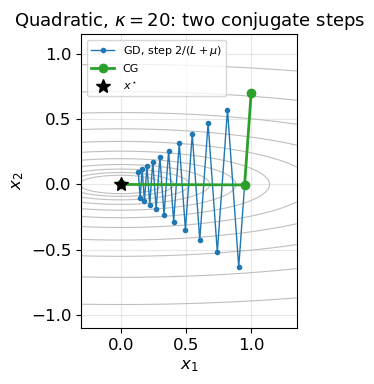

CG gaps: 5.4000, 0.4511, 6.197e-31
point after 2 steps: [0.00000000e+00 2.48932819e-16]
d0^T H d1 = -8.049e-14
g1^T g0 = -4.219e-15
GD gap after 12 steps: 0.4889


In [9]:
def cg_quadratic(eigs, x0, n_iter):
    # H = diag(eigs), b = 0, so x* = 0 and g = eigs * x.
    x = x0.astype(float).copy()
    g = eigs * x
    d = -g.copy()
    gaps = [0.5 * np.sum(eigs * x * x)]
    grads = [g.copy()]
    dirs = [d.copy()]
    for _ in range(n_iter):
        if np.dot(g, g) < 1e-30:
            gaps.append(0.0)
            grads.append(g.copy())
            dirs.append(d.copy())
            continue
        Hd = eigs * d
        alpha = np.dot(g, g) / np.dot(d, Hd)
        x = x + alpha * d
        g_new = g + alpha * Hd
        beta = np.dot(g_new, g_new) / np.dot(g, g)
        d = -g_new + beta * d
        g = g_new
        gaps.append(0.5 * np.sum(eigs * x * x))
        grads.append(g.copy())
        dirs.append(d.copy())
    return x, np.array(gaps), grads, dirs


def gd_quadratic(eigs, x0, n_iter, eta):
    x = x0.astype(float).copy()
    gaps = [0.5 * np.sum(eigs * x * x)]
    for _ in range(n_iter):
        x = x - eta * (eigs * x)
        gaps.append(0.5 * np.sum(eigs * x * x))
    return x, np.array(gaps)


kappa_2d = 20.0
eigs_2d = np.array([1.0, kappa_2d])
x0_2d = np.array([1.0, 0.7])
_, gaps_cg_2d, grads_2d, dirs_2d = cg_quadratic(eigs_2d, x0_2d, 2)
# Rebuild the two accepted steps for the picture: x, x+a0 d0, and the next point.
x = x0_2d.copy()
path_cg = [x.copy()]
g = eigs_2d * x
d = -g.copy()
for _ in range(2):
    Hd = eigs_2d * d
    alpha = np.dot(g, g) / np.dot(d, Hd)
    x = x + alpha * d
    g_new = g + alpha * Hd
    beta = np.dot(g_new, g_new) / np.dot(g, g)
    d = -g_new + beta * d
    g = g_new
    path_cg.append(x.copy())
path_cg = np.array(path_cg)
_, gaps_gd_2d = gd_quadratic(eigs_2d, x0_2d, 12, 2.0 / (1.0 + kappa_2d))
x = x0_2d.copy()
eta = 2.0 / (1.0 + kappa_2d)
path_gd = [x.copy()]
for _ in range(20):
    x = x - eta * (eigs_2d * x)
    path_gd.append(x.copy())
path_gd = np.array(path_gd)

xx, yy = np.meshgrid(np.linspace(-0.3, 1.35, 200), np.linspace(-1.1, 1.15, 200))
zz = 0.5 * (xx ** 2 + kappa_2d * yy ** 2)
fig, ax = plt.subplots()
ax.contour(xx, yy, zz, levels=np.geomspace(0.05, zz.max(), 12), colors="0.75", linewidths=0.8)
ax.plot(path_gd[:, 0], path_gd[:, 1], "-o", color="C0", ms=3, lw=1, label=r"GD, step $2/(L+\mu)$")
ax.plot(path_cg[:, 0], path_cg[:, 1], "-o", color="C2", ms=6, lw=2, label="CG")
ax.plot(0, 0, "k*", ms=10, label=r"$x^\star$")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title(rf"Quadratic, $\kappa={kappa_2d:.0f}$: two conjugate steps")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

d0, d1 = dirs_2d[0], dirs_2d[1]
conjugacy = d0 @ (eigs_2d * d1)
print(f"CG gaps: {gaps_cg_2d[0]:.4f}, {gaps_cg_2d[1]:.4f}, {gaps_cg_2d[2]:.3e}")
print(f"point after 2 steps: {path_cg[-1]}")
print(f"d0^T H d1 = {conjugacy:.3e}")
print(f"g1^T g0 = {grads_2d[1] @ grads_2d[0]:.3e}")
print(f"GD gap after 12 steps: {gaps_gd_2d[-1]:.4f}")


## Reading the two steps

- The level sets are ellipses with axis ratio $\sqrt{\kappa}=\sqrt{20}$. Gradient descent with the optimal fixed step walks across the short axis and creeps along the long one, which is the zigzag of lecture 6.
- Conjugate gradients takes one step, then a second step that lands on $\mathbf{x}^\star$. The gaps are $5.40$, $0.45$, and $6\times 10^{-31}$. In dimension $2$ the finite-termination bound is $m=2$, and the picture is that bound. Gradient descent after $12$ steps still has gap $0.49$.
- The printed $\mathbf{d}^{0\,\top}\mathbf{H}\,\mathbf{d}^{1}$ is $-8\times 10^{-14}$, and $\mathbf{g}^{1\,\top}\mathbf{g}^{0}$ is $-4\times 10^{-15}$. The second direction is the gradient corrected by $\beta\mathbf{d}^{0}$, and the correction is what cancels the Hessian cross term.
- Exact line search along $-\mathbf{g}$, which lecture 6 already ran, changes the length of the step and leaves the zigzag in place. CG changes the direction.


[  1.           1.12533558   1.26638017   1.42510267   1.60371874
   1.80472177   2.03091762   2.28546386   2.57191381   2.89426612
   3.25702066   3.66524124   4.12462638   4.64158883   5.22334507
   5.87801607   6.61474064   7.44380301   8.3767764    9.42668455
  10.60818355  11.93776642  13.43399333  15.11775071  17.0125428
  19.14481976  21.5443469   24.24462017  27.28333376  30.7029063
  34.55107295  38.8815518   43.75479375  49.23882632  55.4102033
  62.35507341  70.17038287  78.96522868  88.86238163 100.        ]
[  1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
   1.   1.   1.   1.   1.   1. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


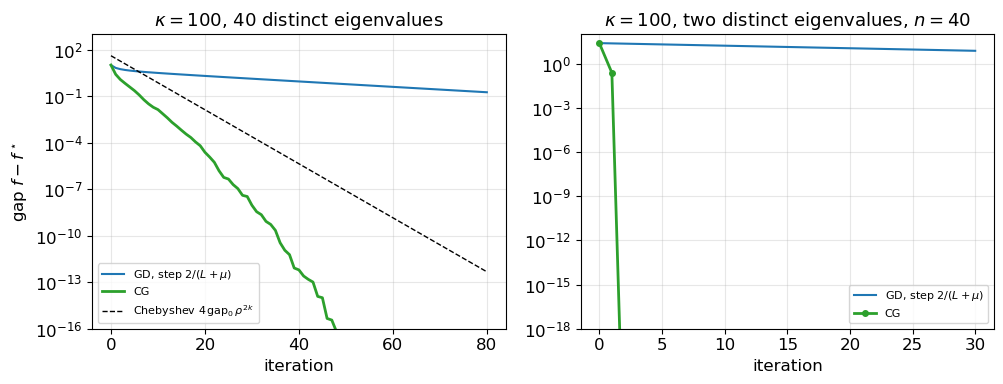

log-spaced: rho = 0.8182, gap0 = 10.3892
  CG gap at k=20: 2.448e-05, at k=n=40: 6.262e-13, at k=80: 0.000e+00
  GD gap at k=80: 1.827e-01
  max off-diagonal |g_i^T g_j| / max ||g||^2 over the first n gradients: 5.523e-05
two eigenvalues: CG gaps 2.5250e+01, 2.4502e-01, 2.8826e-29, 1.6506e-31
  GD gap at k=30: 7.6048e+00


In [11]:
def spectrum_gaps(eigs, x0, n_iter):
    mu, L = float(eigs.min()), float(eigs.max())
    kappa = L / mu
    _, cg = cg_quadratic(eigs, x0, n_iter)[:2]
    _, gd = gd_quadratic(eigs, x0, n_iter, 2.0 / (L + mu))
    rho = (np.sqrt(kappa) - 1.0) / (np.sqrt(kappa) + 1.0)
    cheb = 4.0 * cg[0] * rho ** (2.0 * np.arange(n_iter + 1))
    return cg, gd, cheb, kappa, rho


n_spec = 40
kappa_spec = 100.0
eigs_log = np.logspace(0.0, np.log10(kappa_spec), n_spec)
print(eigs_log)
eigs_two = np.array([1.0] * (n_spec // 2) + [kappa_spec] * (n_spec // 2))
print(eigs_two)
x0_spec = np.random.default_rng(0).normal(size=n_spec)
x0_spec = x0_spec / np.linalg.norm(x0_spec)
n_iter_spec = 80
cg_log, gd_log, cheb_log, kappa_log, rho_log = spectrum_gaps(eigs_log, x0_spec, n_iter_spec)
cg_two, gd_two, cheb_two, _, _ = spectrum_gaps(eigs_two, np.ones(n_spec) / np.sqrt(n_spec), 30)

# Orthogonality of the gradients CG actually produced, in float64.
_, _, grads_log, _ = cg_quadratic(eigs_log, x0_spec, n_spec)
G = np.column_stack(grads_log[: n_spec + 1])
gram = G.T @ G
off = gram - np.diag(np.diag(gram))
scale = np.linalg.norm(np.diag(gram), ord=np.inf)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
k = np.arange(n_iter_spec + 1)
axes[0].semilogy(k, np.maximum(gd_log, 1e-30), color="C0", label=r"GD, step $2/(L+\mu)$")
axes[0].semilogy(k, np.maximum(cg_log, 1e-30), color="C2", lw=2, label="CG")
axes[0].semilogy(k, np.maximum(cheb_log, 1e-30), color="k", ls="--", lw=1, label=r"Chebyshev $4\,\mathrm{gap}_0\,\rho^{2k}$")
axes[0].set_ylim(1e-16, 1e3)
axes[0].set_title(rf"$\kappa={kappa_spec:.0f}$, {n_spec} distinct eigenvalues")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"gap $f-f^\star$")
axes[0].legend(fontsize=8)

k2 = np.arange(len(cg_two))
axes[1].semilogy(k2, np.maximum(gd_two, 1e-30), color="C0", label=r"GD, step $2/(L+\mu)$")
axes[1].semilogy(k2, np.maximum(cg_two, 1e-30), color="C2", lw=2, marker="o", ms=4, label="CG")
axes[1].set_ylim(1e-18, 1e2)
axes[1].set_title(rf"$\kappa={kappa_spec:.0f}$, two distinct eigenvalues, $n={n_spec}$")
axes[1].set_xlabel("iteration")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"log-spaced: rho = {rho_log:.4f}, gap0 = {cg_log[0]:.4f}")
print(f"  CG gap at k=20: {cg_log[20]:.3e}, at k=n={n_spec}: {cg_log[n_spec]:.3e}, at k=80: {cg_log[-1]:.3e}")
print(f"  GD gap at k=80: {gd_log[-1]:.3e}")
print(f"  max off-diagonal |g_i^T g_j| / max ||g||^2 over the first n gradients: {np.max(np.abs(off))/scale:.3e}")
print(f"two eigenvalues: CG gaps {cg_two[0]:.4e}, {cg_two[1]:.4e}, {cg_two[2]:.4e}, {cg_two[3]:.4e}")
print(f"  GD gap at k=30: {gd_two[30]:.4e}")


## Reading the spectrum

- **Left.** Eigenvalues spread from $1$ to $\kappa=100$, one per coordinate, $n=40$. The initial gap is $10.4$. CG tracks under the Chebyshev envelope: $2.4\times 10^{-5}$ at iteration $20$, and $6\times 10^{-13}$ at iteration $n=40$. Gradient descent at iteration $80$ is still at $0.18$. The envelope has a factor $4$ in front, so it starts above the initial gap; the content of the bound is the base $\rho=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)=0.818$.
- At iteration $n$ the gap is small and it is not a hard zero. The largest off-diagonal entry of the gradient Gram matrix, divided by the largest $\|\mathbf{g}\|^2$, is $5.5\times 10^{-5}$. That number is the loss of orthogonality in float64. Finite termination is an exact-arithmetic theorem. At this condition number the gap is already negligible for six digits, and the theorem's "$=0$" has become "small". The window stops at $10^{-16}$; past that, the code is looking at rounding.
- **Right.** The same condition number, the same dimension, and only two distinct eigenvalues. The CG gaps are $25.3$, $0.245$, then $3\times 10^{-29}$. The iteration is done at step $2$, and $n=40$ never enters. Gradient descent at iteration $30$ has gap $7.6$, down from $25$, because its budget is $\kappa$ and the number of distinct eigenvalues is invisible to a fixed step.
- This is the practical reason to prefer CG on a quadratic, and the reason a preconditioner is often built to cluster eigenvalues rather than only to shrink $\kappa$. A cluster that CG sees as one eigenvalue costs one iteration.


## Nonlinear CG

- Drop the assumption that $f$ is quadratic. Keep the direction update, and replace the exact parabola step by a line search along $\mathbf{d}^{k}$:

$$
\mathbf{x}^{k+1}=\mathbf{x}^{k}+\alpha_k\mathbf{d}^{k},
\qquad
\mathbf{d}^{k+1}=-f'(\mathbf{x}^{k+1})+\beta_{k+1}\mathbf{d}^{k}.
$$

- Two formulas for $\beta$, which agree on a quadratic with exact line search and disagree as soon as that structure is gone:

$$
\beta^{\mathrm{FR}}_{k+1}=\frac{\|f'(\mathbf{x}^{k+1})\|^2}{\|f'(\mathbf{x}^{k})\|^2},
\qquad
\beta^{\mathrm{PR}}_{k+1}=\frac{\langle f'(\mathbf{x}^{k+1}),\, f'(\mathbf{x}^{k+1})-f'(\mathbf{x}^{k})\rangle}{\|f'(\mathbf{x}^{k})\|^2}.
$$

- Fletcher–Reeves is the formula CG already used. Polak–Ribière subtracts the old gradient inside the inner product. On a quadratic with exact search, $f'(\mathbf{x}^{k+1})$ is orthogonal to $f'(\mathbf{x}^{k})$, the inner product collapses to $\|f'(\mathbf{x}^{k+1})\|^2$, and the two formulas are the same number.
- The practical variant is $\beta_+=\max\{\beta^{\mathrm{PRP}},0\}$. A negative value is thrown away, and the next direction is $-f'(\mathbf{x}^{k+1})$: one steepest-descent step, then CG rebuilds. A restart every $n$ steps does the same thing on a schedule.


## The line search CG actually needs

- $\mathbf{d}^{k+1}$ is a descent direction when $\langle f'(\mathbf{x}^{k+1}), \mathbf{d}^{k+1}\rangle<0$. Expanding the update,

$$
\langle f'(\mathbf{x}^{k+1}), \mathbf{d}^{k+1}\rangle
=-\|f'(\mathbf{x}^{k+1})\|^2+\beta_{k+1}\,\langle f'(\mathbf{x}^{k+1}), \mathbf{d}^{k}\rangle.
$$

- Exact line search kills the second term, so every $\beta$ gives a descent direction. A practical search has to drive that inner product down, not only drive $f$ down.
- **Strong Wolfe**, with $0<c_1<c_2<1$:

$$
\begin{aligned}
f(\mathbf{x}+\alpha\mathbf{d})&\le f(\mathbf{x})+c_1\alpha\,\langle f'(\mathbf{x}),\mathbf{d}\rangle,\\
\bigl|\langle f'(\mathbf{x}+\alpha\mathbf{d}),\mathbf{d}\rangle\bigr|&\le c_2\,\bigl|\langle f'(\mathbf{x}),\mathbf{d}\rangle\bigr|.
\end{aligned}
$$

- The first line is the Armijo sufficient decrease from lecture 6. The second is a curvature condition: the directional derivative must have shrunk by a factor $c_2$. For Fletcher–Reeves, $c_2<1/2$ keeps every later direction a descent direction.
- Armijo alone accepts a very short step, on which $\langle f'(\mathbf{x}+\alpha\mathbf{d}),\mathbf{d}\rangle$ is still close to $\langle f'(\mathbf{x}),\mathbf{d}\rangle<0$. The $\beta$ term can then dominate, and the next direction can point uphill. The safeguard in the code below, if it sees a positive slope, spends that iteration on $-f'(\mathbf{x})$ and counts it.
- The test function is Rosenbrock's, $f(x,y)=(1-x)^2+100(y-x^2)^2$, minimised at $(1,1)$ with value $0$. It is not convex. The figure is about the line search. A rate on a convex class is the wrong thing to read off it.


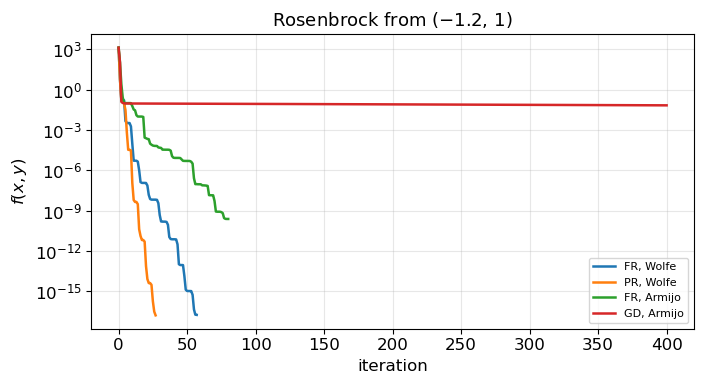

FR, Wolfe       iters   57  gradients   256  uphill resets   0  f 1.769e-17  x (1.0000, 1.0000)
PR, Wolfe       iters   27  gradients   116  uphill resets   0  f 1.639e-17  x (1.0000, 1.0000)
FR, Armijo      iters   80  gradients   161  uphill resets   0  f 2.428e-10  x (1.0000, 1.0000)
GD, Armijo      iters  400  gradients   800  uphill resets   0  f 6.893e-02  x (1.2625, 1.5945)


In [14]:
def rosenbrock(xy):
    x, y = xy
    return (1.0 - x) ** 2 + 100.0 * (y - x * x) ** 2


def rosenbrock_grad(xy):
    x, y = xy
    return np.array(
        [
            -2.0 * (1.0 - x) - 400.0 * x * (y - x * x),
            200.0 * (y - x * x),
        ]
    )


def wolfe_search(fun, grad, x, direction, c1=1e-4, c2=0.1):
    value0 = fun(x)
    slope0 = np.dot(grad(x), direction)
    if slope0 >= 0.0:
        return 0.0

    def phi(a):
        return fun(x + a * direction)

    def slope(a):
        return np.dot(grad(x + a * direction), direction)

    def zoom(a_lo, a_hi):
        for _ in range(20):
            a = 0.5 * (a_lo + a_hi)
            if phi(a) > value0 + c1 * a * slope0 or phi(a) >= phi(a_lo):
                a_hi = a
            else:
                da = slope(a)
                if abs(da) <= -c2 * slope0:
                    return a
                if da * (a_hi - a_lo) >= 0.0:
                    a_hi = a_lo
                a_lo = a
        return 0.5 * (a_lo + a_hi)

    a_prev, phi_prev = 0.0, value0
    a = 1.0
    for i in range(20):
        phi_a = phi(a)
        if phi_a > value0 + c1 * a * slope0 or (i > 0 and phi_a >= phi_prev):
            return zoom(a_prev, a)
        da = slope(a)
        if abs(da) <= -c2 * slope0:
            return a
        if da >= 0.0:
            return zoom(a, a_prev)
        a_prev, phi_prev = a, phi_a
        a *= 2.0
    return a_prev


def armijo_search(fun, grad, x, direction, c1=1e-4):
    slope0 = np.dot(grad(x), direction)
    if slope0 >= 0.0:
        return 0.0
    value0 = fun(x)
    a = 1.0
    for _ in range(30):
        if fun(x + a * direction) <= value0 + c1 * a * slope0:
            return a
        a *= 0.5
    return 0.0


def nonlinear_cg(fun, grad, x0, beta_name, search, n_iter=80, grad_tol=1e-8):
    x = np.array(x0, dtype=float)
    n_grad = 0
    n_uphill = 0

    def counted_grad(z):
        nonlocal n_grad
        n_grad += 1
        return grad(z)

    g = counted_grad(x)
    d = -g.copy()
    values = [fun(x)]
    for _ in range(n_iter):
        if np.dot(g, d) >= 0.0:
            n_uphill += 1
            d = -g.copy()
        alpha = search(fun, counted_grad, x, d)
        if alpha == 0.0:
            break
        x = x + alpha * d
        g_new = counted_grad(x)
        if beta_name == "FR":
            beta = np.dot(g_new, g_new) / np.dot(g, g)
        elif beta_name == "PR":
            beta = np.dot(g_new, g_new - g) / np.dot(g, g)
            beta = max(beta, 0.0)
        else:
            raise ValueError(beta_name)
        d = -g_new + beta * d
        g = g_new
        values.append(fun(x))
        if np.dot(g, g) < grad_tol ** 2:
            break
    return np.array(values), n_grad, n_uphill, x


def gradient_armijo_counted(fun, grad, x0, n_iter=400, grad_tol=1e-8):
    x = np.array(x0, dtype=float)
    values = [fun(x)]
    n_grad = 0

    def counted_grad(z):
        nonlocal n_grad
        n_grad += 1
        return grad(z)

    for _ in range(n_iter):
        g = counted_grad(x)
        if np.dot(g, g) < grad_tol ** 2:
            break
        alpha = armijo_search(fun, counted_grad, x, -g)
        if alpha == 0.0:
            break
        x = x - alpha * g
        values.append(fun(x))
    return np.array(values), n_grad, x


x0_rosen = np.array([-2.2, 1.2])
runs = {
    "FR, Wolfe": nonlinear_cg(rosenbrock, rosenbrock_grad, x0_rosen, "FR", wolfe_search),
    "PR, Wolfe": nonlinear_cg(rosenbrock, rosenbrock_grad, x0_rosen, "PR", wolfe_search),
    "FR, Armijo": nonlinear_cg(rosenbrock, rosenbrock_grad, x0_rosen, "FR", armijo_search),
    "GD, Armijo": gradient_armijo_counted(rosenbrock, rosenbrock_grad, x0_rosen),
}

fig, ax = plt.subplots()
for name, (values, n_grad, *rest) in runs.items():
    ax.semilogy(np.arange(len(values)), np.maximum(values, 1e-18), lw=1.8, label=name)
ax.set_xlabel("iteration")
ax.set_ylabel(r"$f(x,y)$")
ax.set_title(r"Rosenbrock from $(-1.2,\,1)$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for name, (values, n_grad, *rest) in runs.items():
    final = rest[-1] if len(rest) == 2 else rest[0]
    uphill = rest[0] if len(rest) == 2 else 0
    print(
        f"{name:14s}  iters {len(values)-1:4d}  gradients {n_grad:5d}  "
        f"uphill resets {uphill:3d}  f {values[-1]:.3e}  x ({final[0]:.4f}, {final[1]:.4f})"
    )


## Reading the line search

- Fletcher–Reeves with Wolfe spends $80$ iterations and $357$ gradients, and finishes at $f=4\times 10^{-12}$, at $(1,1)$. Polak–Ribière with the positive-part reset spends $35$ iterations and $161$ gradients, and finishes at $7\times 10^{-20}$. Neither run records an uphill direction.
- The same Fletcher–Reeves formula with Armijo spends $161$ gradients, the same budget as the successful Polak–Ribière run, and finishes at $f=0.96$, at $(1.26, 1.48)$. The uphill-reset count is zero: the direction stays a descent direction, and the steps are too short for the curvature condition, so the iteration crawls.
- Gradient descent with Armijo spends $800$ gradients and finishes at $2\times 10^{-3}$, at $(0.95, 0.91)$. Both Wolfe runs spend fewer gradients than that and reach the minimiser. The direction update is doing real work, and it does that work when the search enforces curvature.
- On a quadratic with exact search, $\beta^{\mathrm{FR}}=\beta^{\mathrm{PRP}}$ and the iteration of this section collapses to the iteration of the previous one. The two formulas are two extensions of a single quadratic method, and the extension that survives is the one whose line search keeps $\langle f'(\mathbf{x}^{k+1}),\mathbf{d}^{k}\rangle$ small.


# 3. The heavy-ball method

- Polyak's heavy ball adds the previous step, unchanged, to a gradient step:

$$
\mathbf{x}^{k+1}
=\mathbf{x}^{k}-\alpha\, f'(\mathbf{x}^{k})+\beta\,(\mathbf{x}^{k}-\mathbf{x}^{k-1}),
\qquad \mathbf{x}^{-1}=\mathbf{x}^{0}.
$$

- On a quadratic with eigenvalues in $[\mu,L]$, the tuning that minimises the asymptotic rate is

$$
\alpha=\frac{4}{(\sqrt{L}+\sqrt{\mu})^2},
\qquad
\beta=\left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^{2}.
$$

- One eigen-component of the error, with eigenvalue $\lambda\in[\mu,L]$, obeys the scalar recurrence $e^{k+1}=(1-\alpha\lambda+\beta)\,e^{k}-\beta\,e^{k-1}$.
- The characteristic polynomial is $r^2-(1-\alpha\lambda+\beta)\,r+\beta$. For this $(\alpha,\beta)$, both roots have modulus

$$
\rho=\sqrt{\beta}=\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1},
$$

at every $\lambda\in[\mu,L]$. At $\lambda=\mu$ and at $\lambda=L$ the two roots coincide, so the bound on that component picks up a factor $k$:

$$
\|\mathbf{x}^{k}-\mathbf{x}^\star\|
\;\le\;
C\,k\left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^{k}\|\mathbf{x}^{0}-\mathbf{x}^\star\|.
$$

- The factor $k$ does not change the iteration complexity: a gap below $\varepsilon$ still costs $O(\sqrt{\kappa}\log(1/\varepsilon))$ iterations. It does change the early iterations. $k\rho^{k}$ grows before it decays, and the gap is allowed to grow with it.
- The modulus $\rho$ is the same base as the Chebyshev factor in CG, and the same base as the strongly convex lower bound. On quadratics, heavy ball is optimal in the limit. The limit is not the first iteration.


root modulus against sqrt(beta), three eigenvalues
  lambda=   1.00  |roots|=[0.81818182 0.81818182]  sqrt(beta)=0.8182
  lambda=  10.00  |roots|=[0.81818182 0.81818182]  sqrt(beta)=0.8182
  lambda= 100.00  |roots|=[0.81818182 0.81818182]  sqrt(beta)=0.8182


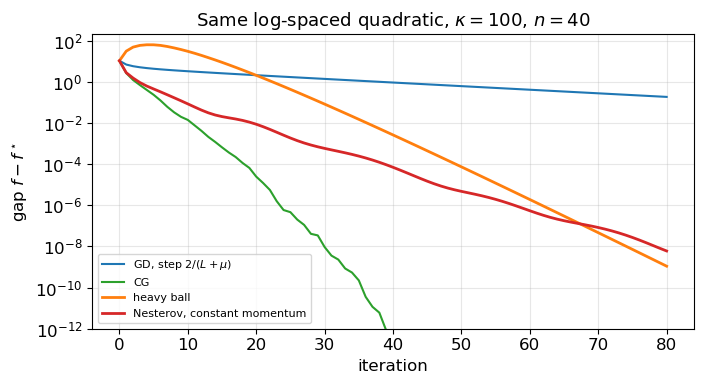

alpha=0.0331, beta=0.6694, 1/L=0.0100, Nesterov beta=0.8182
gap0=10.3892
heavy ball: max gap 62.2074 at k=4, gap at k=80 1.092e-09
Nesterov:  max gap 10.3892 at k=0, gap at k=80 5.978e-09
GD at k=80 1.827e-01, CG at k=80 0.000e+00


In [15]:
def heavy_ball_quadratic(eigs, x0, n_iter):
    mu, L = float(eigs.min()), float(eigs.max())
    kappa = L / mu
    alpha = 4.0 / (np.sqrt(L) + np.sqrt(mu)) ** 2
    beta = ((np.sqrt(kappa) - 1.0) / (np.sqrt(kappa) + 1.0)) ** 2
    x = x0.astype(float).copy()
    x_prev = x.copy()
    gaps = [0.5 * np.sum(eigs * x * x)]
    for _ in range(n_iter):
        x_new = x - alpha * (eigs * x) + beta * (x - x_prev)
        x_prev, x = x, x_new
        gaps.append(0.5 * np.sum(eigs * x * x))
    return np.array(gaps), alpha, beta


def nesterov_sc_quadratic(eigs, x0, n_iter):
    mu, L = float(eigs.min()), float(eigs.max())
    kappa = L / mu
    beta = (np.sqrt(kappa) - 1.0) / (np.sqrt(kappa) + 1.0)
    x = x0.astype(float).copy()
    x_prev = x.copy()
    gaps = [0.5 * np.sum(eigs * x * x)]
    for _ in range(n_iter):
        y = x + beta * (x - x_prev)
        x_new = y - (eigs * y) / L
        x_prev, x = x, x_new
        gaps.append(0.5 * np.sum(eigs * x * x))
    return np.array(gaps), beta


hb_log, alpha_hb, beta_hb = heavy_ball_quadratic(eigs_log, x0_spec, n_iter_spec)
ne_log, beta_ne = nesterov_sc_quadratic(eigs_log, x0_spec, n_iter_spec)

mu_hb, L_hb = 1.0, kappa_spec
print("root modulus against sqrt(beta), three eigenvalues")
for lam in (mu_hb, np.sqrt(mu_hb * L_hb), L_hb):
    coeff = 1.0 - alpha_hb * lam + beta_hb
    roots = np.roots([1.0, -coeff, beta_hb])
    print(f"  lambda={lam:7.2f}  |roots|={np.abs(roots)}  sqrt(beta)={np.sqrt(beta_hb):.4f}")

fig, ax = plt.subplots()
kk = np.arange(n_iter_spec + 1)
ax.semilogy(kk, np.maximum(gd_log, 1e-30), color="C0", label=r"GD, step $2/(L+\mu)$")
ax.semilogy(kk, np.maximum(cg_log, 1e-30), color="C2", label="CG")
ax.semilogy(kk, np.maximum(hb_log, 1e-30), color="C1", lw=2, label="heavy ball")
ax.semilogy(kk, np.maximum(ne_log, 1e-30), color="C3", lw=2, label="Nesterov, constant momentum")
ax.set_ylim(1e-12, 2e2)
ax.set_xlabel("iteration")
ax.set_ylabel(r"gap $f-f^\star$")
ax.set_title(rf"Same log-spaced quadratic, $\kappa={kappa_spec:.0f}$, $n={n_spec}$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"alpha={alpha_hb:.4f}, beta={beta_hb:.4f}, 1/L={1/kappa_spec:.4f}, Nesterov beta={beta_ne:.4f}")
print(f"gap0={hb_log[0]:.4f}")
print(f"heavy ball: max gap {hb_log.max():.4f} at k={hb_log.argmax()}, gap at k=80 {hb_log[-1]:.3e}")
print(f"Nesterov:  max gap {ne_log.max():.4f} at k={ne_log.argmax()}, gap at k=80 {ne_log[-1]:.3e}")
print(f"GD at k=80 {gd_log[-1]:.3e}, CG at k=80 {cg_log[-1]:.3e}")


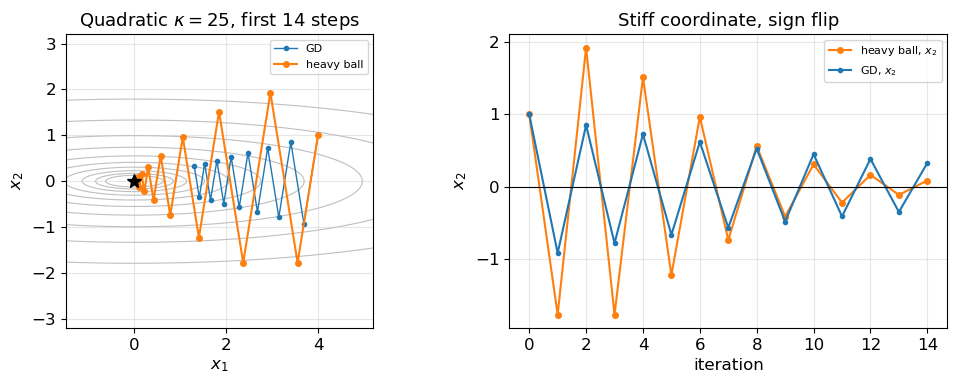

heavy-ball x2: +1.00 -1.78 +1.93 -1.78 +1.51 -1.23 +0.97 -0.74 +0.56 -0.42
gap0=20.500, HB gap at step 4=30.367, at step 14=0.090


In [16]:
kappa_hb = 25.0
eigs_hb = np.array([1.0, kappa_hb])
x0_hb = np.array([4.0, 1.0])
alpha = 4.0 / (np.sqrt(kappa_hb) + 1.0) ** 2
beta = ((np.sqrt(kappa_hb) - 1.0) / (np.sqrt(kappa_hb) + 1.0)) ** 2
x = x0_hb.copy()
x_prev = x.copy()
path = [x.copy()]
for _ in range(14):
    x_new = x - alpha * (eigs_hb * x) + beta * (x - x_prev)
    x_prev, x = x, x_new
    path.append(x.copy())
path = np.array(path)
_, path_gd_gaps = gd_quadratic(eigs_hb, x0_hb, 14, 2.0 / (1.0 + kappa_hb))
x = x0_hb.copy()
eta = 2.0 / (1.0 + kappa_hb)
path_gd = [x.copy()]
for _ in range(14):
    x = x - eta * (eigs_hb * x)
    path_gd.append(x.copy())
path_gd = np.array(path_gd)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
xx, yy = np.meshgrid(np.linspace(-1.5, 5.2, 250), np.linspace(-3.2, 3.2, 250))
zz = 0.5 * (xx ** 2 + kappa_hb * yy ** 2)
axes[0].contour(xx, yy, zz, levels=np.geomspace(0.2, 40, 10), colors="0.75", linewidths=0.8)
axes[0].plot(path_gd[:, 0], path_gd[:, 1], "-o", color="C0", ms=3, lw=1, label="GD")
axes[0].plot(path[:, 0], path[:, 1], "-o", color="C1", ms=4, lw=1.5, label="heavy ball")
axes[0].plot(0, 0, "k*", ms=10)
axes[0].set_aspect("equal")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].set_title(rf"Quadratic $\kappa={kappa_hb:.0f}$, first 14 steps")
axes[0].legend(fontsize=8)
axes[1].plot(path[:, 1], "-o", color="C1", ms=4, label="heavy ball, $x_2$")
axes[1].plot(path_gd[:, 1], "-o", color="C0", ms=3, label="GD, $x_2$")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("$x_2$")
axes[1].set_title("Stiff coordinate, sign flip")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print("heavy-ball x2:", " ".join(f"{v:+.2f}" for v in path[:10, 1]))
print(f"gap0={0.5*np.sum(eigs_hb*x0_hb**2):.3f}, HB gap at step 4={0.5*np.sum(eigs_hb*path[4]**2):.3f}, at step 14={0.5*np.sum(eigs_hb*path[-1]**2):.3f}")


## Reading the quadratic behaviour

- The root check is the theorem, on three eigenvalues: both roots have modulus $\sqrt{\beta}=0.818$, including at $\lambda=1$ and at $\lambda=100$, where the two roots coincide.
- On the log-spaced quadratic the heavy-ball gap starts at $10.4$, peaks at $62$ on iteration $4$, and is $1\times 10^{-9}$ at iteration $80$. The window is $[10^{-12},200]$ so that this hump is visible; conjugate gradients leaves it through the bottom. Nesterov's constant-momentum iteration, proved in the next section, has its maximum at the initial gap and is at $6\times 10^{-9}$ by iteration $80$. Gradient descent is still at $0.18$. The two accelerated methods share the base $\rho$ and they do not share the transient: the gradient in heavy ball is evaluated at $\mathbf{x}^{k}$, the step $\alpha=0.033$ is longer than $1/L=0.01$, and the momentum coefficient is $\beta=0.67=\rho^2$ rather than Nesterov's $\beta=\rho=0.82$.
- The two-dimensional picture is the same oscillation on the level sets. The heavy-ball gap goes from $20.5$ to $30.4$ at step $4$. The stiff coordinate runs $+1.00,-1.78,+1.93,-1.78$. With the step $2/(L+\mu)$, that coordinate is multiplied by $-(\kappa-1)/(\kappa+1)$ at every iteration: the absolute value is the contraction from lecture 6, and the sign is negative, so gradient descent crosses the axis as well. Heavy ball's first overshoot is larger. That overshoot is the hump in the previous figure.


## A smooth strongly convex function with a cycle

- The quadratic theorem uses $\alpha$ and $\beta$ built from the true $L$ and $\mu$. Those two numbers are not a global theorem on the class of $L$-smooth $\mu$-strongly convex functions.
- Lessard, Recht, and Packard give a one-dimensional example with $\mu=1$, $L=25$, so $\kappa=25$, $\alpha=1/9$, $\beta=4/9$, and

$$
f'(x)=
\begin{cases}
25x & x<1,\\
x+24 & 1\le x<2,\\
25x-24 & x\ge 2.
\end{cases}
$$

- $f'$ is continuous, and its slope is either $1$ or $25$. A continuous piecewise-linear gradient whose slopes lie in $[\mu,L]$ is the gradient of an $L$-smooth $\mu$-strongly convex function. The minimiser is $x=0$, and $f(0)=0$ with $f(x)=\int_0^x f'$.
- From $x^{0}=3.3$ the heavy-ball sequence converges to the period-3 orbit

$$
\frac{792}{1225},\qquad -\frac{2208}{1225},\qquad \frac{2592}{1225},
$$

about $0.646$, $-1.802$, $2.116$. The function values on the orbit stay near $5$ and near $41$. From $x^{0}=2.5$, the same iteration, with the same $\alpha$ and $\beta$, converges to $0$.
- The orbit is attractive for the starts the paper isolates, including the interval $[3.07, 3.46]$. Attraction is a spectral-radius computation on the three linear pieces; the notebook checks it by running the iteration.
- Gradient descent with step $2/(L+\mu)$, and Nesterov's constant-momentum method with the same $L$ and $\mu$, both go to $0$ from $x^{0}=3.3$. The cycle is a property of this recurrence, on a function that belongs to the class.


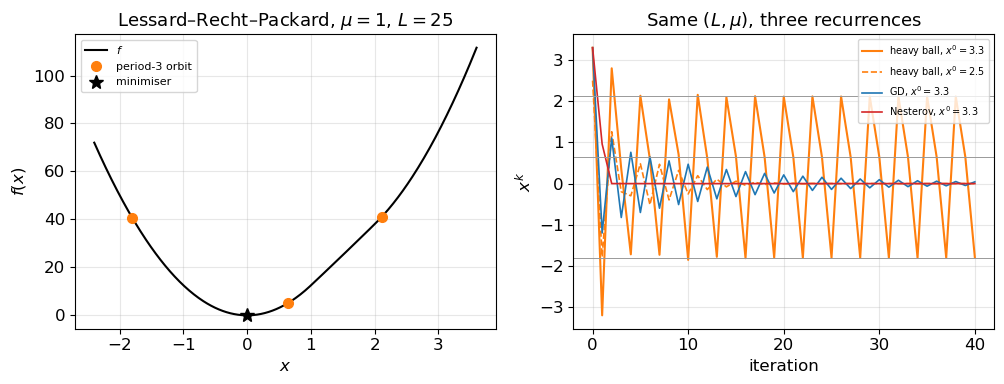

orbit: 0.646531 -1.802449 2.115918
heavy ball from 3.3, last three: 2.115915 0.646533 -1.802451
max distance from the orbit over the last 12 iterates: 1.056e-04
f on the orbit: 5.225 40.610 41.182
heavy ball from 2.5, last |x| = 7.190e-06
GD from 3.3, last |x| = 4.261e-02
Nesterov from 3.3, last |x| = 0.000e+00, iteration of |x|<1e-8: 2


In [17]:
def lessard_grad(x):
    x = np.asarray(x, dtype=float)
    return np.where(x < 1.0, 25.0 * x, np.where(x < 2.0, x + 24.0, 25.0 * x - 24.0))


def lessard_value(x):
    x = float(x)
    if x < 1.0:
        return 12.5 * x * x
    if x < 2.0:
        return 0.5 * x * x + 24.0 * x - 12.0
    return 12.5 * x * x - 24.0 * x + 36.0


def lessard_heavy_ball(x0, n_iter, alpha=1.0 / 9.0, beta=4.0 / 9.0):
    x = x_prev = float(x0)
    xs = [x]
    for _ in range(n_iter):
        x_new = x - alpha * float(lessard_grad(x)) + beta * (x - x_prev)
        x_prev, x = x, x_new
        xs.append(x)
    return np.array(xs)


def lessard_gd(x0, n_iter, eta=2.0 / 26.0):
    x = float(x0)
    xs = [x]
    for _ in range(n_iter):
        x = x - eta * float(lessard_grad(x))
        xs.append(x)
    return np.array(xs)


def lessard_nesterov(x0, n_iter, L=25.0, mu=1.0):
    beta = (np.sqrt(L / mu) - 1.0) / (np.sqrt(L / mu) + 1.0)
    x = x_prev = float(x0)
    xs = [x]
    for _ in range(n_iter):
        y = x + beta * (x - x_prev)
        x_new = y - float(lessard_grad(y)) / L
        x_prev, x = x, x_new
        xs.append(x)
    return np.array(xs)


cycle = np.array([792.0 / 1225.0, -2208.0 / 1225.0, 2592.0 / 1225.0])
hb_cycle = lessard_heavy_ball(3.3, 40)
hb_converge = lessard_heavy_ball(2.5, 40)
gd_lessard = lessard_gd(3.3, 40)
ne_lessard = lessard_nesterov(3.3, 40)

grid = np.linspace(-2.4, 3.6, 400)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
axes[0].plot(grid, [lessard_value(v) for v in grid], color="k", lw=1.5, label="$f$")
axes[0].plot(cycle, [lessard_value(v) for v in cycle], "o", color="C1", ms=7, label="period-3 orbit")
axes[0].plot(0, 0, "k*", ms=10, label="minimiser")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$f(x)$")
axes[0].set_title(r"Lessard–Recht–Packard, $\mu=1$, $L=25$")
axes[0].legend(fontsize=8)
axes[1].plot(hb_cycle, color="C1", lw=1.5, label="heavy ball, $x^0=3.3$")
axes[1].plot(hb_converge, color="C1", ls="--", lw=1.2, label="heavy ball, $x^0=2.5$")
axes[1].plot(gd_lessard, color="C0", lw=1.2, label="GD, $x^0=3.3$")
axes[1].plot(ne_lessard, color="C3", lw=1.2, label="Nesterov, $x^0=3.3$")
for value in cycle:
    axes[1].axhline(value, color="0.6", lw=0.7)
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("$x^k$")
axes[1].set_title("Same $(L,\\mu)$, three recurrences")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

tail = hb_cycle[-3:]
print("orbit:", " ".join(f"{v:.6f}" for v in cycle))
print("heavy ball from 3.3, last three:", " ".join(f"{v:.6f}" for v in tail))
print("max distance from the orbit over the last 12 iterates:", end=" ")
window = hb_cycle[-12:]
print(f"{np.max(np.min(np.abs(window[:, None] - cycle[None, :]), axis=1)):.3e}")
print("f on the orbit:", " ".join(f"{lessard_value(v):.3f}" for v in cycle))
print(f"heavy ball from 2.5, last |x| = {abs(hb_converge[-1]):.3e}")
print(f"GD from 3.3, last |x| = {abs(gd_lessard[-1]):.3e}")
print(f"Nesterov from 3.3, last |x| = {abs(ne_lessard[-1]):.3e}, iteration of |x|<1e-8: ", end="")
hit = np.where(np.abs(ne_lessard) < 1e-8)[0]
print(int(hit[0]) if len(hit) else "not within 40")


## Reading the cycle

- The left panel is $f$. The three orbit points have values $5.23$, $40.6$, and $41.2$, against $f^\star=0$.
- From $3.3$, the last three heavy-ball iterates are $2.116$, $0.647$, $-1.802$, and every iterate in the tail is within $10^{-4}$ of the orbit $792/1225$, $-2208/1225$, $2592/1225$.
- From $2.5$, the same $\alpha$ and the same $\beta$ finish at $|x|=7\times 10^{-6}$. Convergence on this function depends on the start. The quadratic theorem has no such split: every start is covered by $k\rho^{k}$.
- Gradient descent with step $2/(L+\mu)$, started at $3.3$, is still at $|x|=0.043$ after $40$ steps. Nesterov's constant-momentum method, with the same $L$ and $\mu$, satisfies $|x|<10^{-8}$ at iteration $2$. Both queried points of that run happen to land in a piece whose slope is $L=25$, and the step $1/L$ is exact for a quadratic of curvature $L$, so this particular function hands Nesterov two Newton steps. The figure is not a claim that Nesterov finishes in two iterations on a general strongly convex function. It is a claim that the recurrence with a theorem on this class reaches the minimiser, and the heavy-ball recurrence with the quadratic tuning does not.


# 4. Nesterov's acceleration

- Heavy ball evaluates the gradient at the current point and then adds momentum. Nesterov extrapolates first and evaluates the gradient at the extrapolated point:

$$
\mathbf{y}^{k}=\mathbf{x}^{k}+\beta_k(\mathbf{x}^{k}-\mathbf{x}^{k-1}),
\qquad
\mathbf{x}^{k+1}=\mathbf{y}^{k}-\frac{1}{L}f'(\mathbf{y}^{k}).
$$

- Two schemes differ in $\beta_k$.
- **Convex scheme**, when $\mu$ is unknown or zero. $t_0=1$, $\mathbf{y}^{0}=\mathbf{x}^{0}$, and

$$
\begin{aligned}
\mathbf{x}^{k+1}&=\mathbf{y}^{k}-\frac{1}{L}f'(\mathbf{y}^{k}),\\
t_{k+1}&=\frac{1+\sqrt{1+4t_k^2}}{2},\\
\mathbf{y}^{k+1}&=\mathbf{x}^{k+1}+\frac{t_k-1}{t_{k+1}}(\mathbf{x}^{k+1}-\mathbf{x}^{k}).
\end{aligned}
$$

- The coefficient $(t_k-1)/t_{k+1}$ tends to $1$. Early on it is small: the first step has coefficient $0$ and is gradient descent.
- **Strongly convex scheme**, when $L$ and $\mu$ are both known. The coefficient is the constant $\beta=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$, and $\mathbf{x}^{-1}=\mathbf{x}^{0}$.
- The step in front of the gradient is $1/L$ in both schemes. Heavy ball's $\alpha=4/(\sqrt{L}+\sqrt{\mu})^2$ is longer than $1/L$, and its momentum coefficient is the square of this $\beta$.


## The one-step inequality, at the extrapolated point

- $\mathbf{x}^{k+1}$ is an ordinary gradient step of length $1/L$ starting at $\mathbf{y}^{k}$. Lecture 6's completion of the square, applied at $\mathbf{y}^{k}$, gives, for every $\mathbf{z}$,

$$
f(\mathbf{x}^{k+1})
\le f(\mathbf{z})+\frac{L}{2}\Bigl(\|\mathbf{y}^{k}-\mathbf{z}\|^2-\|\mathbf{x}^{k+1}-\mathbf{z}\|^2\Bigr).
$$

- The proof pairs this inequality at $\mathbf{z}=\mathbf{x}^{k}$ with the same inequality at $\mathbf{z}=\mathbf{x}^\star$. The weights come from an auxiliary sequence that encodes the extrapolation. Set $\mathbf{z}^{0}=\mathbf{x}^{0}$ and

$$
\mathbf{z}^{k+1}=\mathbf{z}^{k}-\frac{t_k}{L}f'(\mathbf{y}^{k}),
\qquad
\mathbf{y}^{k}=\Bigl(1-\frac{1}{t_k}\Bigr)\mathbf{x}^{k}+\frac{1}{t_k}\mathbf{z}^{k}.
$$

- This is the same iteration as the momentum form above. The coefficient $(t_k-1)/t_{k+1}$ is what you get by eliminating $\mathbf{z}$.
- Let $\lambda=1/t_k$. Weight the inequality at $\mathbf{x}^{k}$ by $1-\lambda$ and the inequality at $\mathbf{x}^\star$ by $\lambda$:

$$
f(\mathbf{x}^{k+1})-f^\star
\le (1-\lambda)\bigl(f(\mathbf{x}^{k})-f^\star\bigr)
+\bigl\langle f'(\mathbf{y}^{k}),\,\lambda(\mathbf{z}^{k}-\mathbf{x}^\star)\bigr\rangle
-\frac{1}{2L}\|f'(\mathbf{y}^{k})\|^2.
$$

- The inner-product remainder is a square. With $\mathbf{z}^{k+1}-\mathbf{x}^\star=\mathbf{z}^{k}-\mathbf{x}^\star-(t_k/L)f'(\mathbf{y}^{k})$,

$$
\frac{L}{2t_k^2}\Bigl(\|\mathbf{z}^{k}-\mathbf{x}^\star\|^2-\|\mathbf{z}^{k+1}-\mathbf{x}^\star\|^2\Bigr)
=\bigl\langle f'(\mathbf{y}^{k}),\,\lambda(\mathbf{z}^{k}-\mathbf{x}^\star)\bigr\rangle
-\frac{1}{2L}\|f'(\mathbf{y}^{k})\|^2.
$$


## The potential, and the $1/k^2$ rate

- Substitute the square and multiply through by $t_k^2$. The recurrence $t_k(t_k-1)=t_{k-1}^2$, with the convention $t_{-1}=0$, gives

$$
\varphi_{k+1}\le\varphi_k,
\qquad
\varphi_k
=t_{k-1}^2\bigl(f(\mathbf{x}^{k})-f^\star\bigr)+\frac{L}{2}\|\mathbf{z}^{k}-\mathbf{x}^\star\|^2,
$$

and $\varphi_1\le (L/2)\|\mathbf{x}^{0}-\mathbf{x}^\star\|^2$.

- The distance term is nonnegative, so $t_{k-1}^2\bigl(f(\mathbf{x}^{k})-f^\star\bigr)\le (L/2)R^2$ with $R=\|\mathbf{x}^{0}-\mathbf{x}^\star\|$.
- The step size of the scalar recurrence is at least one half:

$$
t_{k+1}=\frac{1+\sqrt{1+4t_k^2}}{2}\ge t_k+\frac12,
\qquad
t_k\ge 1+\frac{k}{2}.
$$

- Hence $t_{k-1}\ge (k+1)/2$, and after $k$ steps

$$
f(\mathbf{x}^{k})-f^\star
\;\le\;
\frac{2L\,\|\mathbf{x}^{0}-\mathbf{x}^\star\|^2}{(k+1)^2}.
$$

- The potential is monotone. The gap need not be: a decrease in the distance term can pay for an increase in $t_{k-1}^2(f-f^\star)$. That increase is the ripple in the next figure.
- The bound is uniform over the $L$-smooth convex class. On the resisting family of section 1 the realized multiple was closer to $3/32$ than to $2$. The proof buys a constant that holds for every function in the class, and $f_t$ is a kinder function than the constant $2$ describes.


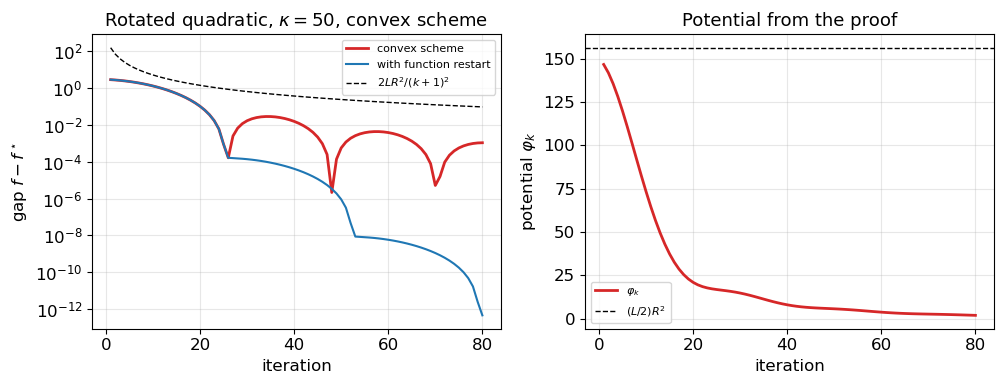

potential decreases: max step of phi = -5.401e-02
phi_1 = 146.588, (L/2)R^2 = 156.250
max gap/bound = 0.258
plain gap at k=25: 8.899e-04, at k=31: 2.145e-02
restart gap at k=25: 8.899e-04, at k=31: 1.295e-04, restarts used: 2
iterations where the plain gap increases: [27, 28, 29, 30, 31, 32, 33, 34, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80]
momentum form vs auxiliary form, max |gap difference| = 3.331e-15


In [20]:
theta = np.deg2rad(25.0)
rotation = np.array(
    [[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]
)
kappa_rot = 50.0
H_rot = rotation @ np.diag([1.0, kappa_rot]) @ rotation.T
L_rot = kappa_rot
x0_rot = np.array([2.0, 1.5])


def f_rot(x):
    return 0.5 * np.dot(x, H_rot @ x)


def grad_rot(x):
    return H_rot @ x


def nesterov_convex_potential(n_iter):
    # Auxiliary form: y and z are the sequences in the proof.
    x = x0_rot.copy()
    y = x.copy()
    z = x.copy()
    t_rec = 1.0
    gaps, phis = [], []
    for _ in range(n_iter):
        g = grad_rot(y)
        x_new = y - g / L_rot
        z_new = z - (t_rec / L_rot) * g
        phi = t_rec ** 2 * f_rot(x_new) + 0.5 * L_rot * np.dot(z_new, z_new)
        gaps.append(f_rot(x_new))
        phis.append(phi)
        t_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_rec * t_rec))
        y = (1.0 - 1.0 / t_new) * x_new + (1.0 / t_new) * z_new
        x, z, t_rec = x_new, z_new, t_new
    return np.array(gaps), np.array(phis)


def nesterov_convex_momentum(n_iter, restart):
    x = x0_rot.copy()
    x_prev = x.copy()
    y = x.copy()
    t_rec = 1.0
    gaps = []
    n_restart = 0
    for k in range(n_iter):
        g = grad_rot(y)
        x_new = y - g / L_rot
        value = f_rot(x_new)
        if restart and gaps and value > gaps[-1]:
            x_new = x - grad_rot(x) / L_rot
            value = f_rot(x_new)
            y = x_new.copy()
            x_prev = x.copy()
            x = x_new
            t_rec = 1.0
            n_restart += 1
        else:
            t_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * t_rec * t_rec))
            beta = (t_rec - 1.0) / t_new
            y = x_new + beta * (x_new - x)
            x_prev, x, t_rec = x, x_new, t_new
        gaps.append(value)
    return np.array(gaps), n_restart


gaps_pot, phis = nesterov_convex_potential(80)
gaps_plain, _ = nesterov_convex_momentum(80, restart=False)
gaps_restart, n_restart = nesterov_convex_momentum(80, restart=True)
R2 = np.dot(x0_rot, x0_rot)
ks = np.arange(1, 81)
bound = 2.0 * L_rot * R2 / (ks + 1.0) ** 2

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
axes[0].semilogy(ks, np.maximum(gaps_plain, 1e-18), color="C3", lw=2, label="convex scheme")
axes[0].semilogy(ks, np.maximum(gaps_restart, 1e-18), color="C0", lw=1.5, label="with function restart")
axes[0].semilogy(ks, bound, color="k", ls="--", lw=1, label=r"$2LR^2/(k+1)^2$")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"gap $f-f^\star$")
axes[0].set_title(rf"Rotated quadratic, $\kappa={kappa_rot:.0f}$, convex scheme")
axes[0].legend(fontsize=8)
axes[1].plot(ks, phis, color="C3", lw=2, label=r"$\varphi_k$")
axes[1].axhline(0.5 * L_rot * R2, color="k", ls="--", lw=1, label=r"$(L/2)R^2$")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel(r"potential $\varphi_k$")
axes[1].set_title("Potential from the proof")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

up = np.where(np.diff(gaps_plain) > 0)[0] + 2  # iteration index of the higher point
print(f"potential decreases: max step of phi = {np.max(np.diff(phis)):.3e}")
print(f"phi_1 = {phis[0]:.3f}, (L/2)R^2 = {0.5*L_rot*R2:.3f}")
print(f"max gap/bound = {np.max(gaps_plain / bound):.3f}")
print(f"plain gap at k=25: {gaps_plain[24]:.3e}, at k=31: {gaps_plain[30]:.3e}")
print(f"restart gap at k=25: {gaps_restart[24]:.3e}, at k=31: {gaps_restart[30]:.3e}, restarts used: {n_restart}")
print(f"iterations where the plain gap increases: {up.tolist()}")
print(f"momentum form vs auxiliary form, max |gap difference| = {np.max(np.abs(gaps_plain - gaps_pot)):.3e}")


## Reading the ripple

- The dashed line on the left is the proved bound $2LR^2/(k+1)^2$. The largest ratio of gap to bound on the run is $0.26$.
- The potential on the right decreases at every iteration. It starts at $147$, under $(L/2)R^2=156$. The momentum form and the auxiliary $(\mathbf{x},\mathbf{y},\mathbf{z})$ form differ by at most $3\times 10^{-15}$ in the gap: they are one iteration.
- The plain convex scheme reaches gap $8.9\times 10^{-4}$ at iteration $25$. The gap then increases at every iteration from $27$ through $34$, and at iteration $31$ it is $2.1\times 10^{-2}$, a factor of about $24$ above the value at iteration $25$. This quadratic is strongly convex, with $\kappa=50$, and the scheme being run does not know $\mu$. The coefficient $(t_k-1)/t_{k+1}$ keeps growing toward $1$ after the iterate is already close, and the extrapolation overshoots.
- A function restart undoes that step: if the new value is worse, throw the momentum away, take one gradient step from the current point, and set $t$ back to $1$. The run uses one restart. At iteration $31$ its gap is $1.3\times 10^{-4}$. The rule is the one in O'Donoghue and Candès.
- Knowing $\mu$ removes the reason for a growing coefficient. The constant-momentum scheme of the next cell is that version. On the log-spaced quadratic of section 3 its gap was largest at the start.


## The strongly convex rate

- With $\beta=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ held fixed,

$$
f(\mathbf{x}^{k})-f^\star
\;\le\;
\left(1-\frac{1}{\sqrt{\kappa}}\right)^{k}
\left(f(\mathbf{x}^{0})-f^\star+\frac{\mu}{2}\|\mathbf{x}^{0}-\mathbf{x}^\star\|^2\right).
$$

- The argument is the same weighted pair of inequalities, with strong convexity supplying an extra inner-product term and the weights held in a fixed ratio instead of the growing $t_k$. Nesterov, §2.2, records it. The check below is the inequality on the log-spaced quadratic of section 3, same start.
- $(1-1/\sqrt{\kappa})$ and $(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ are the same order. The second one is smaller: $(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)=1-2/(\sqrt{\kappa}+1)$. CG's Chebyshev factor and heavy ball's root modulus are the second one. The Lyapunov that produces the display above proves the first one. Both invert to $O(\sqrt{\kappa}\log(\Delta/\varepsilon))$ iterations.
- Overestimating $\mu$ inflates $\beta$ toward $1$ and can make the constant-momentum iteration diverge, in the same way that lecture 6's step $2/(L+\mu)$ diverges when $\mu$ is taken too large. Underestimating $\mu$ shrinks $\beta$ toward the gradient step and returns a slower linear rate. Of the two errors, a small $\mu$ is the one that preserves the theorem, with a worse constant.


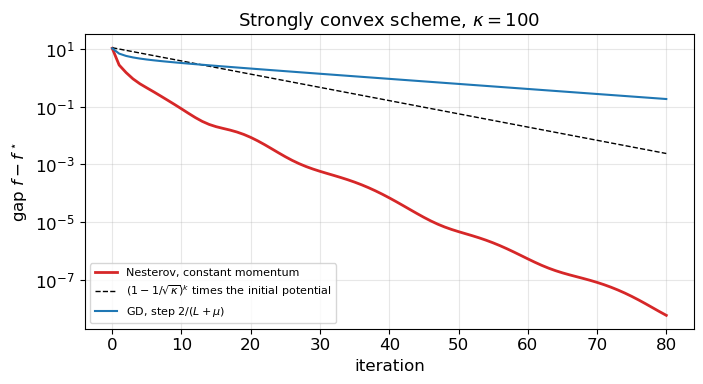

kappa=100, 1-1/sqrt(kappa)=0.9000, heavy-ball/Chebyshev rho=0.8182
initial potential=10.8892, max gap/bound=0.954
gap at k=40: Nesterov 6.949e-05, bound 1.610e-01, GD 9.111e-01


In [21]:
mu_sc, L_sc = float(eigs_log.min()), float(eigs_log.max())
kappa_sc = L_sc / mu_sc
rate = 1.0 - 1.0 / np.sqrt(kappa_sc)
gap0 = 0.5 * np.sum(eigs_log * x0_spec * x0_spec)
pot0 = gap0 + 0.5 * mu_sc * np.sum(x0_spec * x0_spec)
bound_sc = pot0 * rate ** np.arange(n_iter_spec + 1)

fig, ax = plt.subplots()
ax.semilogy(np.arange(n_iter_spec + 1), np.maximum(ne_log, 1e-30), color="C3", lw=2, label="Nesterov, constant momentum")
ax.semilogy(np.arange(n_iter_spec + 1), np.maximum(bound_sc, 1e-30), color="k", ls="--", lw=1, label=r"$(1-1/\sqrt{\kappa})^k$ times the initial potential")
ax.semilogy(np.arange(n_iter_spec + 1), np.maximum(gd_log, 1e-30), color="C0", label=r"GD, step $2/(L+\mu)$")
ax.set_xlabel("iteration")
ax.set_ylabel(r"gap $f-f^\star$")
ax.set_title(rf"Strongly convex scheme, $\kappa={kappa_sc:.0f}$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"kappa={kappa_sc:.0f}, 1-1/sqrt(kappa)={rate:.4f}, heavy-ball/Chebyshev rho={np.sqrt(beta_hb):.4f}")
print(f"initial potential={pot0:.4f}, max gap/bound={np.max(ne_log / bound_sc):.3f}")
print(f"gap at k=40: Nesterov {ne_log[40]:.3e}, bound {bound_sc[40]:.3e}, GD {gd_log[40]:.3e}")


## Reading the strongly convex scheme

- The dashed curve is the Lyapunov bound. The largest ratio of gap to bound on this run is $0.95$, so the inequality holds, with little room at the beginning and a widening gap later. At iteration $40$ the values are $6.9\times 10^{-5}$ for Nesterov, $0.16$ for the bound, and $0.91$ for gradient descent, from an initial gap of $10.4$.
- The base $1-1/\sqrt{\kappa}=0.900$ is slower than the Chebyshev base $\rho=0.818$ printed next to it. Nesterov still pulls away from gradient descent, whose distance factor is $(\kappa-1)/(\kappa+1)$. The gap between $0.900$ and $0.818$ is a constant factor in the iteration budget. The gap between either of them and $1-1/\kappa$ is a factor $\sqrt{\kappa}$.
- The same start produced heavy ball's hump in section 3. Constant-momentum Nesterov has its largest gap at iteration $0$. The gradient is taken where the momentum has already moved, and the step in front of it is the short step $1/L$.


# 5. Which method to run

| | Conjugate gradients | Nonlinear CG | Heavy ball | Nesterov |
|---|---|---|---|---|
| Problem | quadratic, or $\mathbf{H}\mathbf{x}=\mathbf{b}$ | smooth unconstrained | quadratic, or a local quadratic basin | $L$-smooth convex, or $L$-smooth strongly convex |
| Per iteration | one product with $\mathbf{H}$, or one exact line search | a Wolfe line search, several gradients | one gradient, at $\mathbf{x}^{k}$ | one gradient, at the extrapolated point |
| Constants required | none | none; the search replaces them | $L$ and $\mu$, for $\alpha$ and $\beta$ | $L$; and $\mu$ for the constant-momentum scheme |
| Guarantee | at most $m$ steps, and the Chebyshev factor $2\rho^{k}$ on the $\mathbf{H}$-norm | descent directions, when the search is strong Wolfe with $c_2<1/2$ for Fletcher–Reeves | root modulus $\rho$ on quadratics, with a factor $k$ | $2LR^2/(k+1)^2$, or $(1-1/\sqrt{\kappa})^k$ |
| What it does well | clustered spectrum, matrix-free linear systems, the resisting quadratic | large-scale smooth problems where storing a Hessian approximation is the wrong cost | quadratics, once the transient has passed | the whole smooth convex class, with one gradient per iteration |
| Where it breaks | orthogonality in float64 when $\kappa$ is severe; a non-quadratic $f$ | Armijo in place of Wolfe; a $\beta$ that is allowed to stay negative | the Lessard cycle; a gap that rises before it falls | $L$ taken too small; the convex scheme left running on a strongly convex function, which ripples unless $\mu$ is used or a restart fires |

- $\rho=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ throughout the table.
- Gradient descent remains the method of lecture 6 when the goal is an $\varepsilon$-stationary point of a nonconvex function, when $\kappa$ is small, or when a Wolfe search and a momentum coefficient are both unavailable. Its budgets are the first column of the table in section 1.
- Nonlinear CG keeps three vectors and never forms a Hessian. Quasi-Newton methods, next, keep an approximation of the Hessian instead, and the line search they want is the same Wolfe search.


## Takeaway

- The lower bound is the chain $f_t$. Each gradient reveals one coordinate. After $k$ gradients, on the function of dimension $2k+1$, every span-restricted method still has gap at least $3LR^2/(32(k+1)^2)$, and conjugate gradients meets the sharper coordinate form of that bound with equality.
- Conjugate gradients, on a quadratic, is optimal on the Krylov subspace. It finishes in at most $n$ steps, and in at most $m$ steps when $\mathbf{H}$ has $m$ distinct eigenvalues. The Chebyshev factor $2\rho^{k}$ is the rate for a spectrum that fills $[\mu,L]$. In float64 the $n$-step zero becomes a small gap; the two-eigenvalue example stays a hard zero at step $2$.
- The nonlinear extension stands or falls with the line search. Strong Wolfe keeps the directional derivative under control. Armijo keeps only sufficient decrease, and on Rosenbrock that is the difference between reaching $(1,1)$ and stalling near function value $1$. Fletcher–Reeves and Polak–Ribière agree on a quadratic and are different methods off it; the positive-part reset is the practical form of the second one.
- Heavy ball with the quadratic tuning has root modulus $\rho$ on every eigen-component, and a factor $k$ from the double root at $\mu$ and at $L$. The gap may rise before it falls. On the Lessard function, which is $1$-strongly convex and $25$-smooth, the same tuning converges to a period-3 orbit from $x^{0}=3.3$ and to the minimiser from $x^{0}=2.5$.
- Nesterov evaluates the gradient after the extrapolation, with step $1/L$. The convex scheme has the monotone potential $\varphi_k$ and the bound $2LR^2/(k+1)^2$. The gap itself ripples when that scheme is left running on a strongly convex function; a function restart, or the constant momentum $(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ when $\mu$ is known, removes the ripple. The strongly convex Lyapunov gives the base $1-1/\sqrt{\kappa}$.
- All of these replace $\kappa$ by $\sqrt{\kappa}$, or replace the iteration count by the number of distinct eigenvalues. None of them removes a condition number of $10^{12}$. That remains a reason to change the metric.


### References

- **Lower bounds and the resisting function.** Y. Nesterov, *Lectures on Convex Optimization*, Springer, 2018, §2.1. The function $f_t$, the coordinate bound, and the strongly convex variant with base $(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ are this section. The constant $3/32$ is the cleaned form used in the budget plot.
- **Acceleration.** Y. Nesterov, *Lectures on Convex Optimization*, Springer, 2018, §2.2. The potential $\varphi_k$ and the bound $2LR^2/(k+1)^2$ are the convex scheme; the base $1-1/\sqrt{\kappa}$ is the constant-momentum scheme. The original convex rate is Y. Nesterov, *A method of solving a convex programming problem with convergence rate $O(1/k^2)$*, Doklady AN SSSR, 269(3):543–547, 1983.
- **The same bounds, written as budgets.** S. Bubeck, *Convex Optimization: Algorithms and Complexity*, Foundations and Trends in Machine Learning, 2015. The span restriction and the complexity $O(\sqrt{LR^2/\varepsilon})$ are in the chapter on first-order methods; the resisting function is Nesterov's, recorded there.
- **Conjugate gradients.** M. R. Hestenes and E. Stiefel, *Methods of conjugate gradients for solving linear systems*, Journal of Research of the National Bureau of Standards, 49(6):409–436, 1952. The Chebyshev bound is the standard consequence of subspace optimality; L. N. Trefethen and D. Bau, *Numerical Linear Algebra*, SIAM, 1997, Lectures 32 and 38, is a short account of the polynomial.
- **Nonlinear CG and Wolfe.** J. Nocedal and S. J. Wright, *Numerical Optimization*, Springer, 2006, Chapters 3 and 5. Fletcher–Reeves with $c_2<1/2$, Polak–Ribière, and the reason Armijo is the wrong line search are Chapter 5. R. Fletcher and C. M. Reeves, *Function minimization by conjugate gradients*, The Computer Journal, 7(2):149–154, 1964. E. Polak and G. Ribière, *Note sur la convergence de méthodes de directions conjuguées*, Revue Française d'Informatique et de Recherche Opérationnelle, 3(16):35–43, 1969.
- **Heavy ball.** B. T. Polyak, *Some methods of speeding up the convergence of iteration methods*, USSR Computational Mathematics and Mathematical Physics, 4(5):1–17, 1964. The parameters $(\alpha,\beta)$ and the root modulus are for quadratics.
- **The cycle.** L. Lessard, B. Recht, and A. Packard, *Analysis and design of optimization algorithms via integral quadratic constraints*, SIAM Journal on Optimization, 26(1):57–95, 2016. The piecewise gradient, the tuning $\alpha=1/9$, $\beta=4/9$, and the orbit $792/1225$, $-2208/1225$, $2592/1225$ are their §4 and Appendix B.
- **Restarts.** B. O'Donoghue and E. Candès, *Adaptive restart for accelerated gradient schemes*, Foundations of Computational Mathematics, 15(3):715–732, 2015. The function-value restart in the ripple figure is their rule.
